In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
target = 'ClosePrice'

def n_months(path):
    return int(re.search(r'(\d+)mo_test', path).group(1))

In [3]:
def metrics(y_true, y_pred):
    ape = np.abs(y_pred - y_true) / y_true
    return {
        'R2': r2_score(y_true, y_pred),
        'MAPE_%': ape.mean() * 100,
        'MdAPE_%': np.median(ape) * 100,
        'MAE_$': mean_absolute_error(y_true, y_pred),
    }

rows = []
for d in sorted(glob.glob('data/sold/split/*mo_test_2026-08'), key=n_months):
    train = pd.read_csv(f'{d}/train.csv')
    test  = pd.read_csv(f'{d}/test.csv')
    X_tr, y_tr = train.drop(columns=target), train[target]
    X_te, y_te = test.drop(columns=target),  test[target]

    m = LinearRegression().fit(X_tr, y_tr)
    pred = m.predict(X_te)
    rows.append({
        'model': 'LinearRegression',
        'n_train_months': n_months(d),
        'n_train_rows': len(X_tr),
        'train_R2': r2_score(y_tr, m.predict(X_tr)),
        **{f'test_{k}': v for k, v in metrics(y_te, pred).items()},
        'neg_preds': int((pred <= 0).sum()),
    }
)

results = pd.DataFrame(rows)
results.to_csv('baseline_results.csv', index=False)
results

,model,n_train_months,n_train_rows,train_R2,test_R2,test_MAPE_%,test_MdAPE_%,test_MAE_$,neg_preds
0,LinearRegression,6,70134,0.655920,0.659182,35.950250,23.629943,369564.539690,314
1,LinearRegression,9,97808,0.670314,0.664683,34.770391,23.161192,360993.106497,287
2,LinearRegression,12,132729,0.670713,0.668208,33.763757,22.949379,354680.815397,268
3,LinearRegression,15,168303,0.672395,0.669692,33.641340,22.905101,353992.007893,259
4,LinearRegression,18,199629,0.679832,0.670306,33.520936,22.551410,351853.932057,242
5,LinearRegression,21,229070,0.680974,0.671726,33.209071,22.353919,349251.178299,239
6,LinearRegression,24,264721,0.682326,0.671960,32.757941,22.060764,346333.373649,228
7,LinearRegression,27,304467,0.687817,0.672797,32.520968,21.913309,344810.781078,227
8,LinearRegression,30,338404,0.690345,0.672546,32.332330,21.854008,343467.729502,219


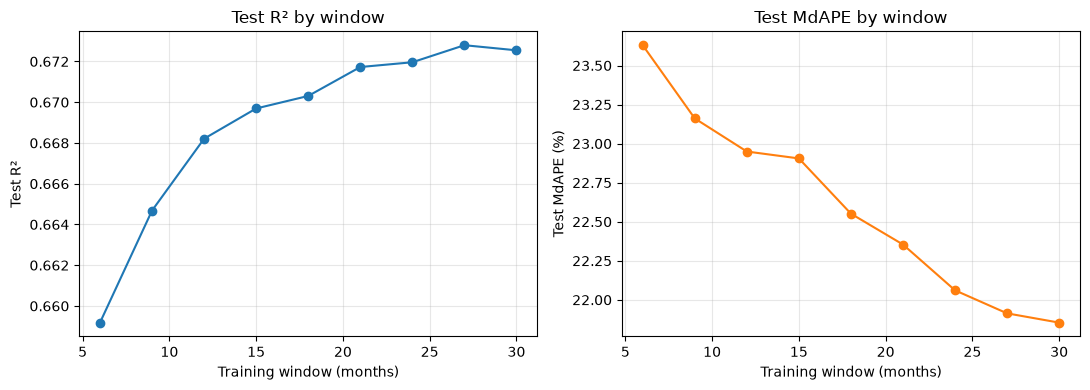

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(results['n_train_months'], results['test_R2'], marker='o')
ax[0].set(xlabel='Training window (months)', ylabel='Test R²', title='Test R² by window')
ax[1].plot(results['n_train_months'], results['test_MdAPE_%'], marker='o', color='tab:orange')
ax[1].set(xlabel='Training window (months)', ylabel='Test MdAPE (%)', title='Test MdAPE by window')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [5]:
BASELINE_N = 24
d = f'data/sold/split/{BASELINE_N}mo_test_2026-08'
train, test = pd.read_csv(f'{d}/train.csv'), pd.read_csv(f'{d}/test.csv')
X_tr, y_tr = train.drop(columns=target), train[target]
X_te, y_te = test.drop(columns=target),  test[target]

lr = LinearRegression().fit(X_tr, y_tr)
pred = lr.predict(X_te)

Points on the red dashed line represent perfect predictions. The linear regression model predicts prices reasonably well for low- to mid-priced homes, but it has two limitations:

* **Underpredicts high-priced properties:** Homes selling above roughly $10M are severely underpredicted, causing those data points to fall far below the line.
* **Generates impossible values:** The model predicts negative prices for 228 of the test homes, which is financially impossible.

This proves that home price is not linear across all features, and a straight-line fit cannot capture the steep price growth seen at the high end of the market.


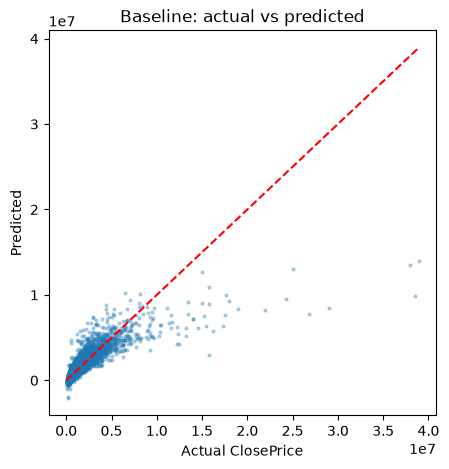

In [6]:
plt.figure(figsize=(5, 5))
plt.scatter(y_te, pred, s=4, alpha=0.3)
lim = [0, y_te.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('Actual ClosePrice'); plt.ylabel('Predicted'); plt.title('Baseline: actual vs predicted')
plt.show()